In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia import fov, RelabelTransform


In [3]:
def show_image(img, seg, title=None):
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(1, 2, 2)
    plt.imshow(seg.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
    plt.show()

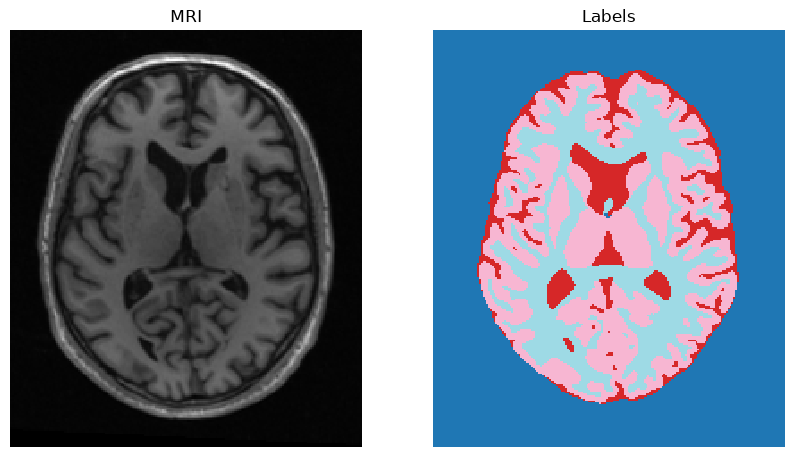

In [4]:
fname_img = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1w.nii.gz"
fname_seg = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1wdseg_synthsr.nii.gz"
# npz = np.load(fname)
# dat = torch.as_tensor(npz['vol'][:, :, 112]).T[None]
# lab = torch.as_tensor(npz['seg'][:, :, 112]).T[None]

seg = nib.load(fname_seg).get_fdata()
img = nib.load(fname_img).get_fdata()

thal = np.argwhere(np.isin(seg, [10, 49]))
cx, cy, cz = thal.mean(0).astype(int) if len(thal) else np.array(seg.shape) // 2

seg = ufs.merge_seg96_to_seg3(seg) #map to 0,1,2,3
dat = torch.as_tensor(np.flipud(img[:, :, cz].T).copy())[None]
lab = torch.as_tensor(np.flipud(seg[:, :, cz].T).copy())[None]

lab = RelabelTransform()(lab) #map to 0,1,2,3,...,N


show_image(dat, lab, title='MRI and Labels')

# plt.figure(figsize=(10, 10))
# plt.subplot(1, 2, 1)
# plt.imshow(dat.squeeze(), cmap='gray', interpolation='nearest')
# plt.axis('off')
# plt.title('MRI')
# plt.subplot(1, 2, 2)
# plt.imshow(lab.squeeze(), cmap='tab20', interpolation='nearest')
# plt.axis('off')
# plt.title('Labels')
# plt.show()

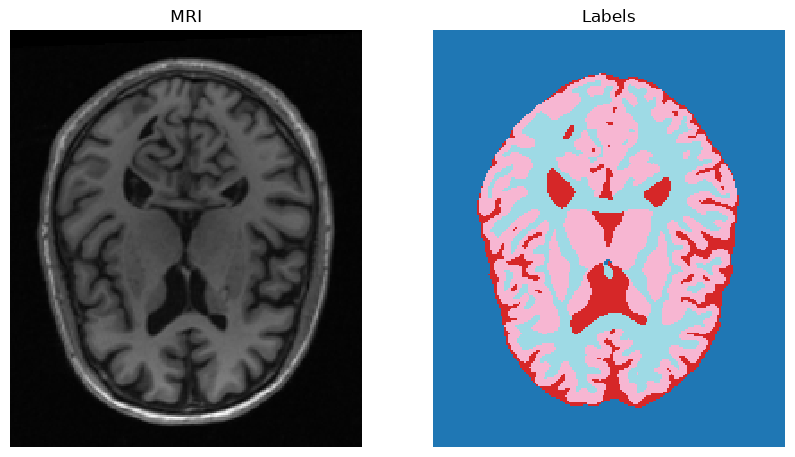

In [5]:
# flip first axis

xform = fov.FlipTransform(1)
flip_dat, flip_lab = xform(dat, lab)

show_image(flip_dat, flip_lab, title='Flipped MRI and Labels')

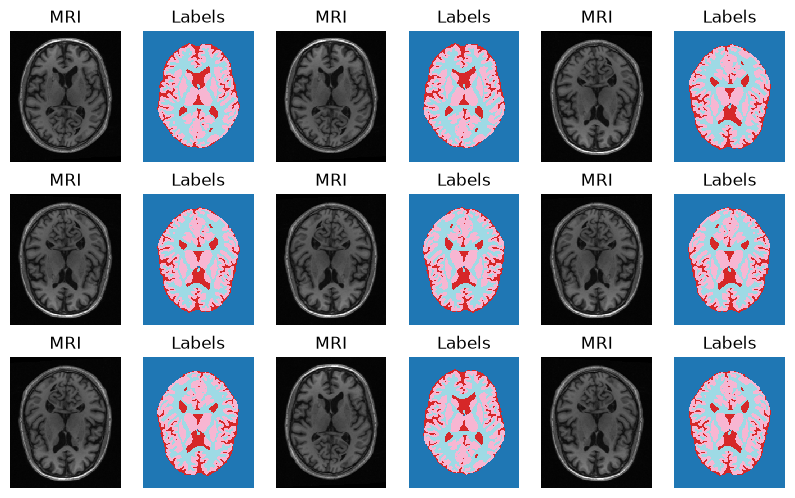

In [6]:
xform = fov.RandomFlipTransform()


plt.figure(figsize=(10, 6))
for i in range(3*3):
    flip_dat, flip_lab = xform(dat, lab)
    plt.subplot(3, 6, 2*i+1)
    plt.imshow(flip_dat.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(3, 6, 2*i+2)
    plt.imshow(flip_lab.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
plt.show()

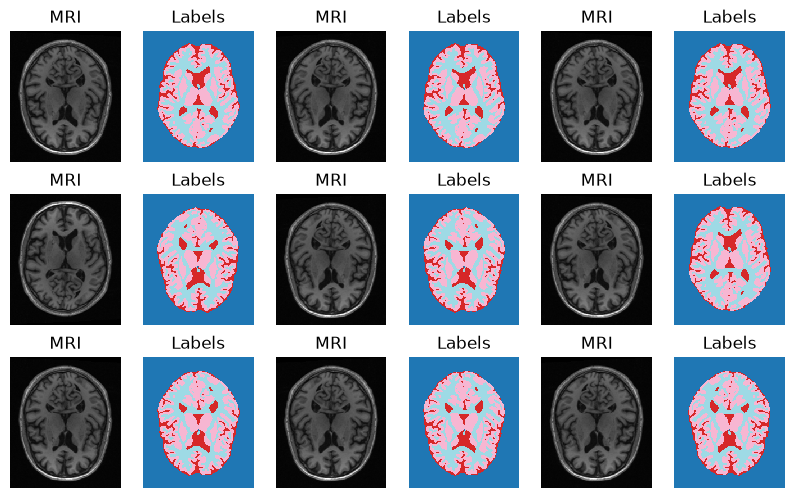

In [7]:
# random flip / different per tensor
xform = fov.RandomFlipTransform(shared='channels')


plt.figure(figsize=(10, 6))
for i in range(3*3):
    flip_dat, flip_lab = xform(dat, lab)
    plt.subplot(3, 6, 2*i+1)
    plt.imshow(flip_dat.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(3, 6, 2*i+2)
    plt.imshow(flip_lab.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
plt.show()

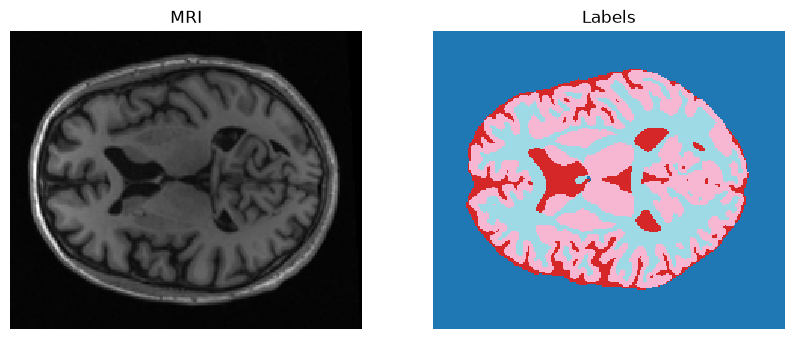

In [8]:
# Permute axes

xform = fov.PermuteAxesTransform()
perm_dat, perm_lab = xform(dat, lab)

plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(perm_dat.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('MRI')
plt.subplot(1, 2, 2)
plt.imshow(perm_lab.squeeze(), cmap='tab20', interpolation='nearest')
plt.axis('off')
plt.title('Labels')
plt.show()

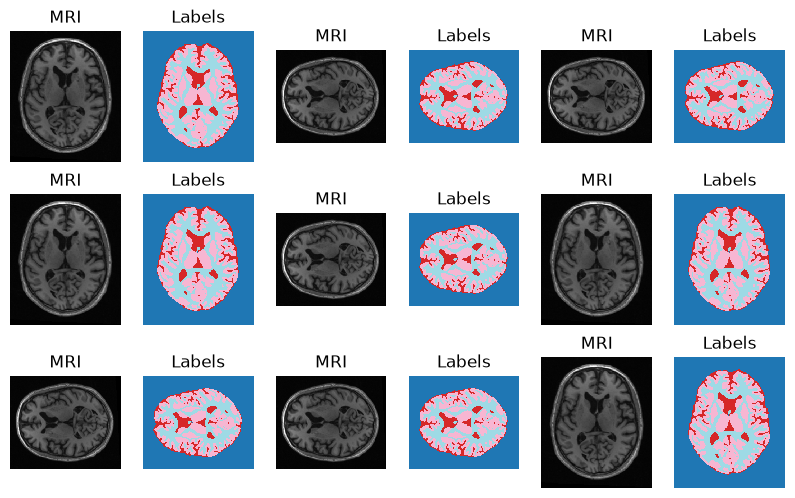

In [9]:
# random permutation
xform = fov.RandomPermuteAxesTransform()


plt.figure(figsize=(10, 6))
for i in range(3*3):
    perm_dat, perm_lab = xform(dat, lab)
    plt.subplot(3, 6, 2*i+1)
    plt.imshow(perm_dat.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(3, 6, 2*i+2)
    plt.imshow(perm_lab.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
plt.show()

Original shape: torch.Size([1, 233, 197]), torch.Size([1, 233, 197])
Transformed shape: torch.Size([1, 256, 256]), torch.Size([1, 256, 256])


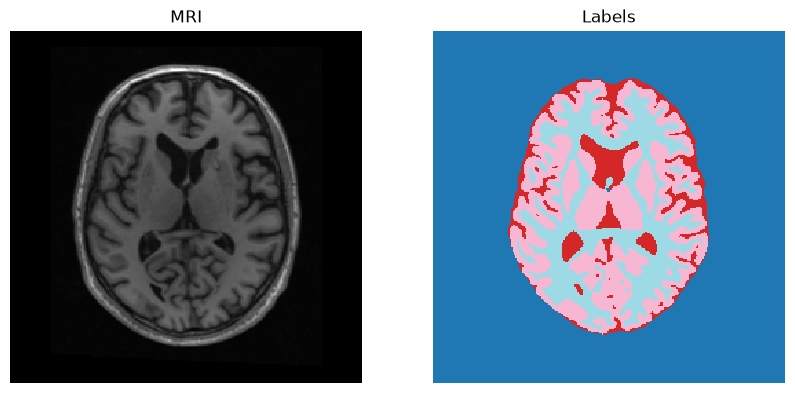

In [24]:
# Ensure size is a power of two (i nerver crops, only pads)
print(f"Original shape: {dat.shape}, {lab.shape}")
xform = fov.PowerTwoTransform(8, bound='zero')
dat2, lab2 = xform(dat, lab)
print(f"Transformed shape: {dat2.shape}, {lab2.shape}")

show_image(dat2, lab2, title='Power of Two MRI and Labels')

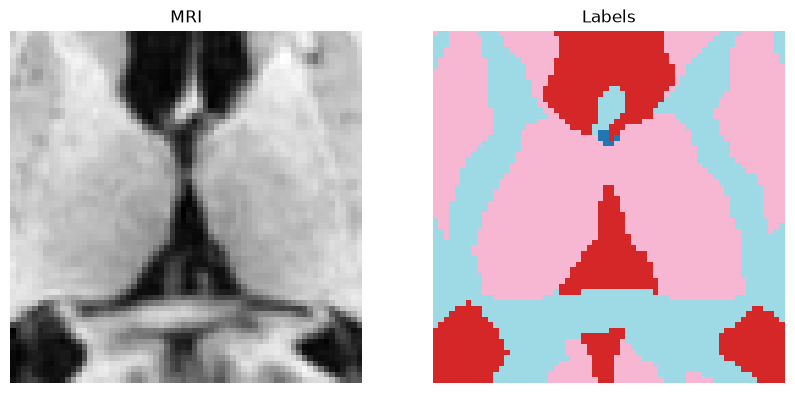

In [ ]:
# Extract a patch, center is in relative coordinates (0,0) is the center of the image, (-1,-1) is the bottom left corner, (1,1) is the top right corner

xform = fov.PatchTransform(shape=(64, 64, 64), center=(0.,0))
dat2, lab2 = xform(dat, lab)

show_image(dat2, lab2, title='Patch MRI and Labels')

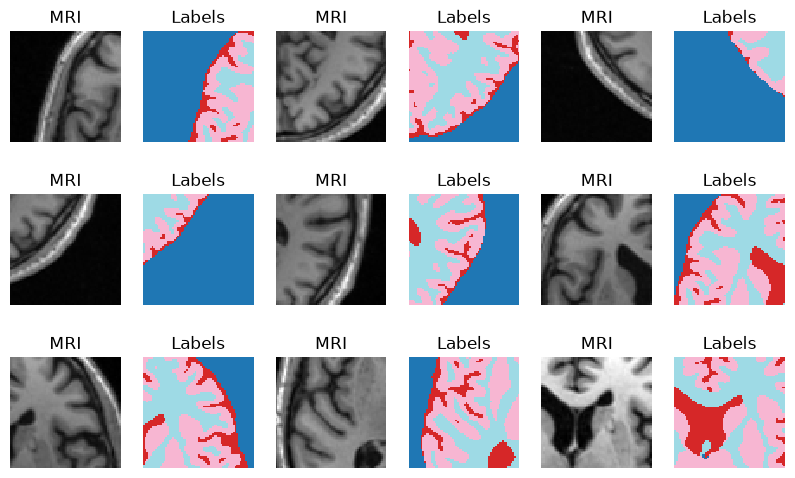

In [51]:
# Extract a random patch

xform = fov.RandomPatchTransform(64)

plt.figure(figsize=(10, 6))
for i in range(3*3):
    patch_dat, patch_lab = xform(dat, lab)
    plt.subplot(3, 6, 2*i+1)
    plt.imshow(patch_dat.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(3, 6, 2*i+2)
    plt.imshow(patch_lab.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
plt.show()